In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Procurement Spend Optimization
## Data Science Case Study

**Objective:** Identify and quantify procurement cost-saving opportunities
while maintaining service quality.

**Dataset:** California State Purchase Orders (2012–2015)

### Business Question

How can we reduce procurement spending by 5% next year
without compromising service quality?

### Analytical Approach

1. Data Understanding
2. Data Quality Assessment
3. Data Cleaning
4. Exploratory Spend Analysis
5. Procurement Optimization Opportunities
6. Savings Estimation
7. Confidence Assessment
8. Business Recommendations

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid")


In [8]:
from pathlib import Path
import re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 45)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
OUT = Path('resultats_procurement'); OUT.mkdir(exist_ok=True)

CSV_PATH = Path('purchase-order-data-2012-2015-.csv')
if not CSV_PATH.exists():
    CSV_PATH = Path('/content/drive/MyDrive/Job /Renault asses/purchase-order-data-2012-2015-.csv')



In [9]:
df_raw = pd.read_csv(CSV_PATH, low_memory=False, dtype={'Supplier Code':'string', 'Purchase Order Number':'string', 'Normalized UNSPSC':'string'})
print('Dimensions :', df_raw.shape)
print('Colonnes :', df_raw.columns.tolist())
display(df_raw.head(3))
missing = (df_raw.isna().mean()*100).sort_values(ascending=False)
display(missing.to_frame('Taux manquant (%)').head(25))



Dimensions : (344504, 32)
Colonnes : ['Creation Date', 'Purchase Date', 'Fiscal Year', 'LPA Number', 'Purchase Order Number', 'Requisition Number', 'Acquisition Type', 'Sub-Acquisition Type', 'Acquisition Method', 'Sub-Acquisition Method', 'Department Name', 'Supplier Code', 'Supplier Name', 'Supplier Qualifications', 'Supplier Zip Code', 'CalCard', 'Item Name', 'Item Description', 'Quantity', 'Unit Price', 'Total Price', 'Classification Codes', 'Normalized UNSPSC', 'Commodity Title', 'Class', 'Class Title', 'Family', 'Family Title', 'Segment', 'Segment Title', 'Location', 'REMOVE AMERISOURCE']


,Creation Date,Purchase Date,Fiscal Year,LPA Number,Purchase Order Number,Requisition Number,Acquisition Type,Sub-Acquisition Type,Acquisition Method,Sub-Acquisition Method,Department Name,Supplier Code,Supplier Name,Supplier Qualifications,Supplier Zip Code,CalCard,Item Name,Item Description,Quantity,Unit Price,Total Price,Classification Codes,Normalized UNSPSC,Commodity Title,Class,Class Title,Family,Family Title,Segment,Segment Title,Location,REMOVE AMERISOURCE
0,8/27/2013,NaN,2013-2014,7-12-70-26,REQ0011118,REQ0011118,IT Goods,NaN,WSCA/Coop,NaN,"Consumer Affairs, Department of",1740272,Pitney Bowes,NaN,NaN,NO,USB,USB,1.00,$1.00,$1.00,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1/29/2014,NaN,2013-2014,NaN,REQ0011932,REQ0011932,NON-IT Goods,NaN,Informal Competitive,NaN,"Consumer Affairs, Department of",1760085,Rodea Auto Tech,NaN,NaN,NO,Tire Disposal,Tire Disposal,2.00,$2.00,$4.00,76121504,76121504,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,11/1/2013,NaN,2013-2014,NaN,REQ0011476,REQ0011476,IT Services,NaN,Informal Competitive,NaN,"Consumer Affairs, Department of",17224,"Smile Business Products, Inc",NaN,95841,NO,Labor,Labor,4.50,$150.00,$675.00,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"95841\n(38.662263, -121.346136)",NaN


,Taux manquant (%)
REMOVE AMERISOURCE,100.00
Requisition Number,95.83
Sub-Acquisition Method,91.04
Sub-Acquisition Type,80.16
LPA Number,73.62
Supplier Qualifications,58.86
Location,20.34
Supplier Zip Code,20.34
Purchase Date,5.06
Family,0.96


## 2. Nettoyage des données, contrôles et analyse des doublons

Certaines lignes présentent exactement les mêmes valeurs, ce qui soulève la question de doublons potentiels. Toutefois, le jeu de données ne contient pas d'identifiant unique pour chaque ligne de commande : deux lignes identiques peuvent donc aussi correspondre à des achats distincts. Avant de décider de les supprimer, j'évalue leur fréquence et leur impact sur les montants totaux. La comparaison des dépenses avant et après une suppression hypothétique permet de quantifier le risque associé à cette décision.


In [10]:
# Identifier et supprimer les colonnes qui ne contiennent que des valeurs nulles
initial_cols = df_raw.shape[1]
df_raw = df_raw.dropna(how='all', axis=1)
print(f"Colonnes supprimées : {initial_cols - df_raw.shape[1]}")
print("Liste des colonnes restantes :", df_raw.columns.tolist())

Colonnes supprimées : 1
Liste des colonnes restantes : ['Creation Date', 'Purchase Date', 'Fiscal Year', 'LPA Number', 'Purchase Order Number', 'Requisition Number', 'Acquisition Type', 'Sub-Acquisition Type', 'Acquisition Method', 'Sub-Acquisition Method', 'Department Name', 'Supplier Code', 'Supplier Name', 'Supplier Qualifications', 'Supplier Zip Code', 'CalCard', 'Item Name', 'Item Description', 'Quantity', 'Unit Price', 'Total Price', 'Classification Codes', 'Normalized UNSPSC', 'Commodity Title', 'Class', 'Class Title', 'Family', 'Family Title', 'Segment', 'Segment Title', 'Location']


In [11]:
print("Number of rows:", df_raw.shape[0])
print("Number of columns:", df_raw.shape[1])

Number of rows: 344504
Number of columns: 31


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Copie des données originales : aucun doublon supprimé
df_clean = df_raw.copy()

# Conversion des colonnes numériques
for col in ["Quantity", "Unit Price", "Total Price"]:
    df_clean[col] = pd.to_numeric(
        df_clean[col].astype("string")
        .str.replace(r"[$,\s]", "", regex=True)
        .str.replace(r"^\((.*)\)$", r"-\1", regex=True),
        errors="coerce"
    )

# Vérification
display(df_clean[["Quantity", "Unit Price", "Total Price"]].head())

,Quantity,Unit Price,Total Price
0,1.00,1.00,1.00
1,2.00,2.00,4.00
2,4.50,150.00,675.00
3,<NA>,<NA>,<NA>
4,1.00,"6,080.26","6,080.26"


In [13]:
df_clean.describe(include='all')

,Creation Date,Purchase Date,Fiscal Year,LPA Number,Purchase Order Number,Requisition Number,Acquisition Type,Sub-Acquisition Type,Acquisition Method,Sub-Acquisition Method,Department Name,Supplier Code,Supplier Name,Supplier Qualifications,Supplier Zip Code,CalCard,Item Name,Item Description,Quantity,Unit Price,Total Price,Classification Codes,Normalized UNSPSC,Commodity Title,Class,Class Title,Family,Family Title,Segment,Segment Title,Location
count,344504,327083,344504,90897,344504,14366,344504,68334,344504,30883,344504,344468,344468,141745,274424,344504,344472,344303,"344,474.00","344,474.00","344,474.00",343487,343487,341211,"341,211.00",341211,"341,211.00",341211,"341,211.00",341211,274424
unique,1015,2266,3,1418,197000,5996,5,25,20,16,111,25235,24728,278,3993,2,179658,218696,<NA>,<NA>,<NA>,45743,13405,13072,NaN,2344,NaN,411,NaN,56,3993
top,6/27/2014,7/1/2014,2013-2014,7-11-51-02,4500211314,REQ0008872,NON-IT Goods,Personal Services,Informal Competitive,Fleet,"Corrections and Rehabilitation, Department of",1743406,Voyager Fleet Systems Inc,CA-MB CA-SB,95691,NO,Medical Supplies,confidential,<NA>,<NA>,<NA>,15101506,15101506,Gasoline or Petrol,NaN,Petroleum and distillates,NaN,Office machines and their supplies and accessories,NaN,Information Technology Broadcasting and Telecommunications,"95691\n(38.575311, -121.560401)"
freq,1531,4433,120158,9267,602,123,213578,16104,82046,14148,57533,13756,13756,53077,11095,339132,2911,1637,<NA>,<NA>,<NA>,12679,12776,12776,NaN,14584,NaN,16478,NaN,32679,11095
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"1,945.78","432,841.75","436,949.88",NaN,NaN,NaN,"49,215,719.22",NaN,"49,211,570.01",NaN,"49,072,122.53",NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"98,198.31","21,411,308.68","21,411,350.93",NaN,NaN,NaN,"22,473,388.78",NaN,"22,476,636.06",NaN,"22,478,617.25",NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,"-30,861,228.00","-30,861,228.00",NaN,NaN,NaN,"10,101,500.00",NaN,"3,018,000.00",NaN,"10,000,000.00",NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.00,34.27,300.00,NaN,NaN,NaN,"39,111,500.00",NaN,"39,110,000.00",NaN,"39,000,000.00",NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.00,540.00,"3,525.39",NaN,NaN,NaN,"44,121,500.00",NaN,"44,120,000.00",NaN,"44,000,000.00",NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.00,"10,000.54","14,616.67",NaN,NaN,NaN,"71,151,000.00",NaN,"71,150,000.00",NaN,"71,000,000.00",NaN,NaN


In [ ]:
#gestion des doublon

In [15]:
# ============================================================
# ANALYSE DE LA QUALITÉ DES DONNÉES : DOUBLONS
# ============================================================
#
# Objectif :
# Identifier les doublons potentiels et mesurer leur impact
# sur les dépenses, sans supprimer automatiquement les lignes.
#
# Hypothèse :
# Deux lignes strictement identiques peuvent correspondre
# à une duplication technique ou à deux achats distincts.
#
#
# ============================================================


# On travaille sur les données originales, sans suppression.
df_analyse = df_clean.copy()

# Identification des occurrences supplémentaires.
# La première occurrence est conservée comme référence.
masque_doublons = df_analyse.duplicated(keep="first")

# Identification de toutes les lignes appartenant
# à un groupe de doublons.
masque_groupes = df_analyse.duplicated(keep=False)

# Nombre de lignes.
nb_lignes = len(df_analyse)
nb_doublons = masque_doublons.sum()
nb_lignes_groupes = masque_groupes.sum()

# Proportion des doublons.
pourcentage_doublons = nb_doublons / nb_lignes * 100

# Dépenses totales déclarées.
depenses_totales = df_analyse["Total Price"].sum()

# Montant associé aux occurrences supplémentaires.
montant_doublons = df_analyse.loc[
    masque_doublons, "Total Price"
].sum()

# Impact financier potentiel.
impact_financier = montant_doublons / depenses_totales * 100

# Scénario alternatif : suppression des occurrences supplémentaires.
depenses_sans_doublons = depenses_totales - montant_doublons

In [16]:
tableau_doublons = pd.DataFrame({
    "Indicateur": [
        "Nombre total de lignes",
        "Occurrences supplémentaires identiques",
        "Lignes appartenant à un groupe de doublons",
        "Proportion de doublons potentiels"
    ],
    "Valeur": [
        f"{nb_lignes:,}",
        f"{nb_doublons:,}",
        f"{nb_lignes_groupes:,}",
        f"{pourcentage_doublons:.2f} %"
    ]
})

display(
    tableau_doublons.style
    .hide(axis="index")
    .set_properties(**{
        "text-align": "left",
        "padding": "10px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        }
    ])
)

Indicateur,Valeur
Nombre total de lignes,"344,504"
Occurrences supplémentaires identiques,"2,087"
Lignes appartenant à un groupe de doublons,"3,392"
Proportion de doublons potentiels,0.61 %


In [17]:
tableau_impact = pd.DataFrame({
    "Indicateur": [
        "Dépenses totales déclarées",
        "Montant des doublons potentiels",
        "Dépenses après suppression hypothétique",
        "Impact sur les dépenses totales"
    ],
    "Valeur": [
        f"{depenses_totales:,.2f} $",
        f"{montant_doublons:,.2f} $",
        f"{depenses_sans_doublons:,.2f} $",
        f"{impact_financier:.4f} %"
    ]
})

display(
    tableau_impact.style
    .hide(axis="index")
    .set_properties(**{
        "text-align": "left",
        "padding": "10px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        }
    ])
)

Indicateur,Valeur
Dépenses totales déclarées,"150,517,871,463.40 $"
Montant des doublons potentiels,"59,874,849.55 $"
Dépenses après suppression hypothétique,"150,457,996,613.85 $"
Impact sur les dépenses totales,0.0398 %


In [19]:
	(59874849.55 / 2330000000)*100

2.569736032188841

In [20]:
# ============================================================
# IMPACT DES DOUBLONS SUR L'OBJECTIF DE RÉDUCTION DE 5 %
# ============================================================

annee_reference = "2014-2015"
taux_reduction = 0.05

# Données de la dernière année.
df_reference = df_analyse[
    df_analyse["Fiscal Year"] == annee_reference
].copy()

# Dépenses déclarées de la dernière année.
budget_reference = df_reference["Total Price"].sum()

# Doublons identifiés dans le dataset complet
# et appartenant à la dernière année.
doublons_reference = masque_doublons.loc[df_reference.index]

# Montant des doublons potentiels de cette année.
montant_doublons_reference = df_reference.loc[
    doublons_reference, "Total Price"
].sum()

# Budget alternatif sans doublons.
budget_sans_doublons = (
    budget_reference - montant_doublons_reference
)

# Objectifs de réduction de 5 %.
objectif_avec_doublons = budget_reference * taux_reduction
objectif_sans_doublons = budget_sans_doublons * taux_reduction

# Différence entre les deux objectifs.
difference_objectif = (
    objectif_avec_doublons - objectif_sans_doublons
)

In [21]:
comparaison = pd.DataFrame({
    "Scénario": [
        "Conservation des doublons",
        "Suppression hypothétique"
    ],
    "Budget de référence ($)": [
        budget_reference,
        budget_sans_doublons
    ],
    "Objectif de réduction de 5 % ($)": [
        objectif_avec_doublons,
        objectif_sans_doublons
    ]
})

display(
    comparaison.style
    .hide(axis="index")
    .format({
        "Budget de référence ($)": "{:,.2f}",
        "Objectif de réduction de 5 % ($)": "{:,.2f}"
    })
    .background_gradient(
        subset=["Objectif de réduction de 5 % ($)"],
        cmap="Blues"
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("padding", "10px")
            ]
        }
    ])
)

Scénario,Budget de référence ($),Objectif de réduction de 5 % ($)
Conservation des doublons,"46,541,293,688.64","2,327,064,684.43"
Suppression hypothétique,"46,525,456,612.92","2,326,272,830.65"


In [22]:
sensibilite = pd.DataFrame({
    "Indicateur": [
        "Année de référence",
        "Montant des doublons potentiels",
        "Différence sur l'objectif de 5 %",
        "Décision retenue"
    ],
    "Résultat": [
        annee_reference,
        f"{montant_doublons_reference:,.2f} $",
        f"{difference_objectif:,.2f} $",
        "Conserver les enregistrements"
    ]
})

display(
    sensibilite.style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("padding", "10px")
            ]
        }
    ])
)

Indicateur,Résultat
Année de référence,2014-2015
Montant des doublons potentiels,"15,837,075.72 $"
Différence sur l'objectif de 5 %,"791,853.79 $"
Décision retenue,Conserver les enregistrements


### Décision concernant les doublons potentiels

J'ai choisi de **conserver les lignes identiques**. Sans identifiant unique de ligne ni confirmation métier, il est impossible d'affirmer qu'il s'agit de doublons réels. Leur nombre ne suffit pas à démontrer une erreur de saisie ; une suppression automatique risquerait donc de sous-estimer les dépenses. Par prudence, ces lignes restent dans l'analyse et sont signalées pour vérification.

Si les équipes Achats confirment ultérieurement qu'il s'agit de commandes comptabilisées plusieurs fois, leur montant pourrait représenter une piste d'économie ou de correction comptable. Le montant associé aux doublons potentiels correspond à environ **2,5 % de l'objectif de réduction de 5 %**, mais **ne constitue pas une économie acquise**.


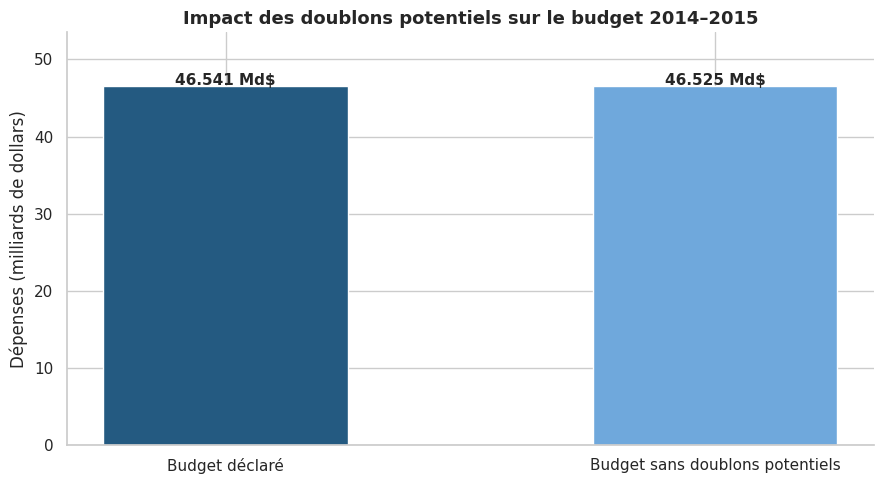

In [23]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

scenarios = [
    "Budget déclaré",
    "Budget sans doublons potentiels"
]

montants = [
    budget_reference / 1e9,
    budget_sans_doublons / 1e9
]

couleurs = ["#245A81", "#6FA8DC"]

barres = ax.bar(
    scenarios,
    montants,
    color=couleurs,
    width=0.5
)

for barre, montant in zip(barres, montants):
    ax.text(
        barre.get_x() + barre.get_width() / 2,
        barre.get_height() + 0.15,
        f"{montant:.3f} Md$",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Impact des doublons potentiels sur le budget 2014–2015",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel("Dépenses (milliards de dollars)")
ax.set_ylim(0, max(montants) * 1.15)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## Vérification de la cohérence des montants

Je compare le montant déclaré (`Total Price`) au montant recalculé (`Quantity × Unit Price`) afin de repérer les écarts éventuels et d'en mesurer l'importance.


In [46]:
# Calcul du montant attendu
df_clean["Montant calculé"] = df_clean["Quantity"] * df_clean["Unit Price"]

# Différence entre montant déclaré et calculé
df_clean["Écart"] = df_clean["Total Price"] - df_clean["Montant calculé"]
df_clean["Écart absolu"] = df_clean["Écart"].abs()

# Une ligne est incohérente si l'écart dépasse 0,01 $
df_clean["Incohérent"] = df_clean["Écart absolu"] > 0.01

# Résumé
resume = pd.DataFrame({
    "Indicateur": ["Lignes totales", "Lignes vérifiables", "Lignes incohérentes",
                   "Taux d'incohérence", "Somme des écarts absolus"],
    "Valeur": [
        len(df_clean),
        df_clean["Écart"].notna().sum(),
        df_clean["Incohérent"].sum(),
        f"{df_clean['Incohérent'].sum() / df_clean['Écart'].notna().sum() * 100:.2f} %",
        f"{df_clean.loc[df_clean['Incohérent'], 'Écart absolu'].sum():,.2f} $"
    ]
})

display(resume.style.hide(axis="index"))


Indicateur,Valeur
Lignes totales,344504
Lignes vérifiables,344474
Lignes incohérentes,4255
Taux d'incohérence,1.24 %
Somme des écarts absolus,"1,406,383.96 $"


In [47]:
analyse_annees = df_clean.groupby("Fiscal Year").agg(
    Lignes=("Incohérent", "size"),
    Verifiables=("Écart", "count"),
    Incoherentes=("Incohérent", "sum"),
    Somme_ecarts=("Écart absolu", lambda x: x[x > 0.01].sum())
)

analyse_annees["Taux (%)"] = (
    analyse_annees["Incoherentes"] / analyse_annees["Verifiables"] * 100
)

display(
    analyse_annees.style
    .format({"Somme_ecarts": "{:,.2f} $", "Taux (%)": "{:.2f} %"})
    .background_gradient(subset=["Taux (%)"], cmap="Oranges")
)

,Lignes,Verifiables,Incoherentes,Somme_ecarts,Taux (%)
Fiscal Year,,,,,
2012-2013,108377,108377,1825,"681,979.38 $",1.68 %
2013-2014,120158,120145,1421,"415,693.59 $",1.18 %
2014-2015,115969,115952,1009,"308,710.99 $",0.87 %


### Évolution des incohérences et règle de traitement

La proportion d'incohérences semble diminuer au fil des années. Cette évolution peut traduire une amélioration des contrôles ou de la saisie des données, **sans permettre de l'affirmer à partir du seul jeu de données**.

Pour les montants manquants, je privilégie une imputation déterministe : lorsque la quantité et le prix unitaire sont disponibles et exploitables, le montant total peut être reconstitué par `Quantity × Unit Price`. Lorsqu'un montant total est déjà renseigné mais diffère du calcul, je ne le remplace pas automatiquement : l'écart doit d'abord être analysé.


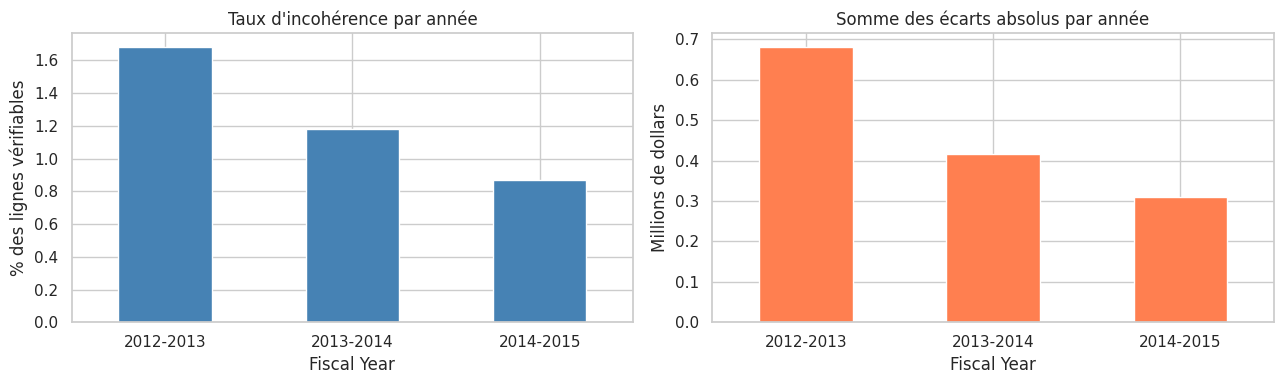

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

analyse_annees["Taux (%)"].plot(
    kind="bar", ax=axes[0], color="steelblue",
    title="Taux d'incohérence par année"
)
axes[0].set_ylabel("% des lignes vérifiables")
axes[0].tick_params(axis="x", rotation=0)

(analyse_annees["Somme_ecarts"] / 1e6).plot(
    kind="bar", ax=axes[1], color="coral",
    title="Somme des écarts absolus par année"
)
axes[1].set_ylabel("Millions de dollars")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [49]:
#visualisation des incoherence
colonnes = [
    "Fiscal Year", "Item Name", "Quantity", "Unit Price",
    "Total Price", "Montant calculé", "Écart"
]

display(
    df_clean[df_clean["Incohérent"]]
    .sort_values("Écart absolu", ascending=False)
    [colonnes].head(10)
    .style.format({
        "Quantity": "{:,.2f}",
        "Unit Price": "{:,.2f}",
        "Total Price": "{:,.2f}",
        "Montant calculé": "{:,.2f}",
        "Écart": "{:,.2f}"
    })
)

,Fiscal Year,Item Name,Quantity,Unit Price,Total Price,Montant calculé,Écart
284694,2012-2013,3-2019 #10 Double Window Envelope,"15,000,000.00",0.00,"192,000.00",0.00,"192,000.00"
32570,2012-2013,#10 Envelope,"15,000,000.00",0.00,"192,000.00",0.00,"192,000.00"
119865,2013-2014,3-2019 #10 Double Window Envelope,"20,000,000.00",0.01,"298,000.00","200,000.00","98,000.00"
167051,2014-2015,3-2019 #10 Double Window Envelope,"15,000,000.00",0.02,"235,500.00","300,000.00","-64,500.00"
74292,2013-2014,3-2019 #10 Double Window Envelope,"20,000,000.00",0.01,"264,000.00","200,000.00","64,000.00"
234135,2013-2014,3-2040 #10 Double Window Time Sensitive Envelope,"10,000,000.00",0.02,"157,000.00","200,000.00","-43,000.00"
247169,2012-2013,Envelope 3-2019,"15,000,000.00",0.01,"189,000.00","150,000.00","39,000.00"
152461,2014-2015,"3-1960 5 3/4""x9"" IHSS Return Envelope (No Travel)","6,545,000.00",0.02,"102,756.50","130,900.00","-28,143.50"
152018,2014-2015,3-1950 IHSS 6x9.5 Booklet Style Outgoing Envelope,"9,408,000.00",0.02,"210,739.20","188,160.00","22,579.20"
39998,2012-2013,Envelope 3-1326 Tall #10 Double Window,"4,500,000.00",0.02,"67,500.00","90,000.00","-22,500.00"


#### 3. Analyse : comprendre les écarts positifs et négatifs

In [50]:
# On utilise uniquement les lignes présentant une incohérence
anomalies = df_clean[df_clean["Incohérent"]].copy()

# Classification selon le signe de l'écart
anomalies["Type écart"] = np.where(
    anomalies["Écart"] > 0,
    "Positif",
    "Négatif"
)

# Résumé
bilan = anomalies.groupby("Type écart").agg(
    Nombre=("Écart", "size"),
    Écart_total=("Écart", "sum"),
    Écart_absolu=("Écart absolu", "sum")
)

display(bilan.style.format({
    "Écart_total": "{:,.2f} $",
    "Écart_absolu": "{:,.2f} $"
}))

,Nombre,Écart_total,Écart_absolu
Type écart,,,
Négatif,2402,"-359,226.70 $","359,226.70 $"
Positif,1853,"1,047,157.26 $","1,047,157.26 $"


In [51]:
analyse_methodes = anomalies.groupby(
    ["Acquisition Method", "Type écart"]
).agg(
    Nombre=("Écart", "size"),
    Montant_ecarts=("Écart absolu", "sum")
).reset_index()

display(
    analyse_methodes.sort_values(
        "Montant_ecarts", ascending=False
    ).head(20).style.format({
        "Montant_ecarts": "{:,.2f} $"
    })
)

,Acquisition Method,Type écart,Nombre,Montant_ecarts
19,SB/DVBE Option,Positif,241,"989,286.78 $"
18,SB/DVBE Option,Négatif,208,"254,089.51 $"
8,Informal Competitive,Négatif,469,"33,992.39 $"
31,Statewide Contract,Négatif,1194,"30,085.94 $"
28,State Programs,Positif,82,"20,304.58 $"
32,Statewide Contract,Positif,760,"15,385.25 $"
27,State Programs,Négatif,64,"12,104.84 $"
4,Fair and Reasonable,Négatif,134,"8,888.68 $"
6,Formal Competitive,Négatif,32,"7,791.25 $"
9,Informal Competitive,Positif,346,"6,304.46 $"


In [52]:
analyse_types = df_clean.groupby("Acquisition Type").agg(
    Lignes=("Incohérent", "size"),
    Incoherences=("Incohérent", "sum"),
    Verifiables=("Écart", "count")
)

analyse_types["Taux (%)"] = (
    analyse_types["Incoherences"]
    / analyse_types["Verifiables"] * 100
)

display(
    analyse_types.sort_values(
        "Taux (%)", ascending=False
    ).style.format({"Taux (%)": "{:.2f} %"})
)

,Lignes,Incoherences,Verifiables,Taux (%)
Acquisition Type,,,,
NON-IT Goods,213578,3859,213548,1.81 %
IT Goods,50896,324,50896,0.64 %
IT Services,11514,23,11514,0.20 %
NON-IT Services,68369,49,68369,0.07 %
IT Telecommunications,147,0,147,0.00 %


Les achats **NON-IT Goods** présentent davantage de lignes incohérentes en valeur absolue. Cette catégorie étant également très représentée dans le jeu de données, il faut distinguer le **nombre d'anomalies** de leur **taux rapporté au nombre de lignes** avant de conclure qu'elle est moins fiable que les autres.


In [53]:
# Recherche de mots-clés dans les descriptions
mots_cles = (
    r"discount|rebate|tax|freight|shipping|"
    r"handling|fee|surcharge|adjustment"
)

anomalies["Indice frais/remise"] = (
    anomalies["Item Description"]
    .fillna("")
    .str.contains(mots_cles, case=False, regex=True)
)

# Afficher les lignes concernées
colonnes = [
    "Fiscal Year", "Item Description", "Department Name", "Supplier Code", "Item Name",
    "Acquisition Method", "Écart", "Type écart"
]

display(
    anomalies[anomalies["Indice frais/remise"]]
    [colonnes].head(30)
)

,Fiscal Year,Item Description,Department Name,Supplier Code,Item Name,Acquisition Method,Écart,Type écart
441,2012-2013,FISH FEED,"Fish and Wildlife, Department of",1006618,#4 CUSTOM TROUT W/VITAMIN BOOST,Statewide Contract,-12.00,Négatif
3279,2012-2013,Starter Fish feed #2,"Fish and Wildlife, Department of",1006618,Fish Feed,Statewide Contract,3.80,Positif
5435,2013-2014,#2 - Sack Feed,"Fish and Wildlife, Department of",1006618,Fish Food,Statewide Contract,38.00,Positif
5851,2012-2013,FISH FEED,"Fish and Wildlife, Department of",1006618,#4 BULK W/VITAMIN BOOST,Statewide Contract,-18.00,Négatif
6062,2012-2013,FISH FEED,"Fish and Wildlife, Department of",1006618,3/16 EXTRA 450 FLOATING,Statewide Contract,116.00,Positif
6064,2012-2013,FISH FEED,"Fish and Wildlife, Department of",1006618,#3 SACK FEED W/VITAMIN BOOST,Statewide Contract,-9.00,Négatif
6419,2012-2013,FISH FEED,"Fish and Wildlife, Department of",1006618,EXTR 450 FLOATING 3/32,Statewide Contract,24.00,Positif
6897,2012-2013,FISH FEED,"Fish and Wildlife, Department of",1006618,EXTR 450 FLOATING 3/16,Statewide Contract,116.00,Positif
7050,2012-2013,"FEDERAL OIL SPILL, CA SPILL FUND, AB 32 FEE'S, FED LUST, FED EXCISE EXEMPT, STATE EXCISE, AND E-...","Developmental Services, Department of",1000707,UNLEADED GASOLINE,Statewide Contract,57.50,Positif
7087,2012-2013,FISH FEED,"Fish and Wildlife, Department of",1006618,CUSTOM TROUT #4 BULK W/VITAMIN BOOST,Statewide Contract,-15.00,Négatif


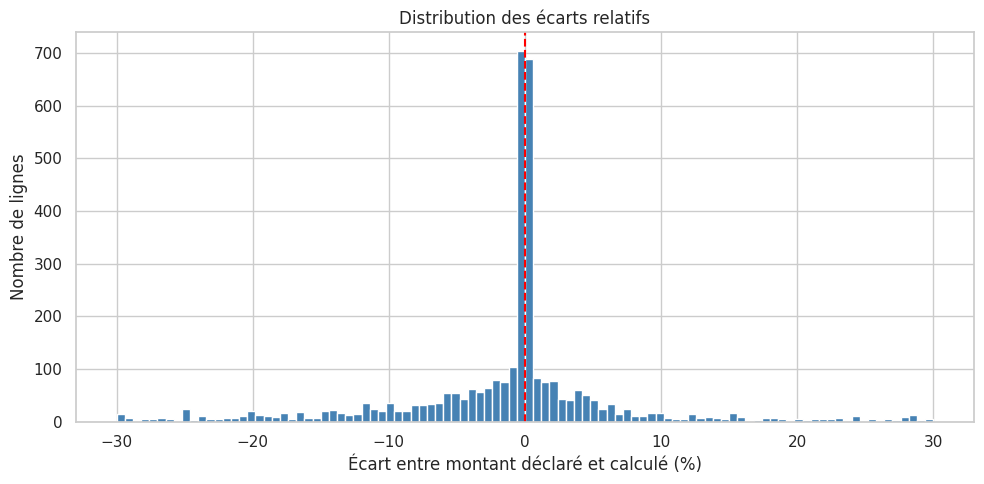

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Zoom entre -30 % et +30 %
ecarts = anomalies["Écart"]
ecarts = ecarts[ecarts.between(-30, 30)]

plt.hist(ecarts, bins=100, color="steelblue", edgecolor="white")

plt.axvline(0, color="red", linestyle="--")

plt.title("Distribution des écarts relatifs")
plt.xlabel("Écart entre montant déclaré et calculé (%)")
plt.ylabel("Nombre de lignes")

plt.tight_layout()
plt.show()

### Investigation des causes possibles

J'ai envisagé que certains écarts positifs ou négatifs puissent provenir de taxes, de frais supplémentaires ou de remises liées aux quantités commandées. Pour explorer cette hypothèse, j'ai examiné la distribution des écarts relatifs et recherché d'éventuelles concentrations autour de taux usuels (par exemple 5 %, 7 % ou 10 %).

Les écarts observés sont surtout concentrés autour de **0 %**. Cela ne met pas en évidence un mécanisme uniforme de taxe ou de remise et rend plausible l'existence d'erreurs de saisie ou d'arrondis. **La cause exacte reste toutefois indéterminée** sans information complémentaire sur les conditions de transaction.


In [57]:
# Arrondir les écarts à 1 décimale
anomalies["Écart arrondi (%)"] = anomalies["Écart"].round(1)

display(
    anomalies["Écart arrondi (%)"]
    .value_counts()
    .head(20)
    .to_frame("Nombre de lignes")
)

,Nombre de lignes
Écart arrondi (%),
-0.00,646
0.10,208
-0.10,195
0.20,85
-0.20,68
0.40,34
-0.30,33
0.30,30
0.50,28


### Décision d'imputation et de conservation

Lorsque `Total Price` est manquant, je le reconstitue à partir de `Quantity × Unit Price` si ces deux informations sont disponibles et valides. Si le montant total est renseigné, je conserve cette information même lorsque la quantité ou le prix unitaire manque. En revanche, si aucun montant de dépense ne peut être établi, la ligne est exclue de l'analyse financière.

Une autre possibilité serait d'estimer un prix à partir d'achats similaires (même produit, même fournisseur), mais cette méthode introduirait une hypothèse supplémentaire : **les prix peuvent évoluer dans le temps et selon les conditions d'achat**. Je ne la retiens donc pas comme règle d'imputation automatique.


In [60]:

# Calcul du montant théorique
df_clean["Montant calculé"] = df_clean["Quantity"] * df_clean["Unit Price"]

# Identification des montants manquants
manquants = df_clean["Total Price"].isna()

# Montants qu'on peut imputer
df_clean["Montant imputé"] = (
    manquants
    & (df_clean["Quantity"] > 0)
    & (df_clean["Unit Price"] > 0)
)

# Imputation uniquement des montants manquants
df_clean.loc[df_clean["Montant imputé"], "Total Price"] = (
    df_clean.loc[df_clean["Montant imputé"], "Montant calculé"]
)

# Lignes impossibles à exploiter financièrement
nb_exclus = df_clean["Total Price"].isna().sum()

# Suppression uniquement des lignes sans montant exploitable
df_clean = df_clean.dropna(subset=["Total Price"]).copy()

# Vérification des incohérences (tolérance de 0,01 $)
df_clean["Écart"] = df_clean["Total Price"] - df_clean["Montant calculé"]
df_clean["Écart absolu"] = df_clean["Écart"].abs()

df_clean["Incohérent"] = (
    (~df_clean["Montant imputé"])
    & (df_clean["Écart absolu"] > 0.01)
)

# Classification
df_clean["Qualité montant"] = "Cohérent"

df_clean.loc[
    df_clean["Montant calculé"].isna(),
    "Qualité montant"
] = "Non vérifiable"

df_clean.loc[
    df_clean["Incohérent"],
    "Qualité montant"
] = "Incohérent"

df_clean.loc[
    df_clean["Montant imputé"],
    "Qualité montant"
] = "Imputé"

In [62]:
bilan = pd.DataFrame({
    "Indicateur": [
        "Lignes initiales",
        "Montants imputés",
        "Lignes exclues",
        "Lignes conservées",
        "Lignes incohérentes",
        "Montant total imputé"
    ],
    "Valeur": [
        "344504",
        df_clean["Montant imputé"].sum(),
        nb_exclus,
        len(df_clean),
        df_clean["Incohérent"].sum(),
        f"{df_clean.loc[df_clean['Montant imputé'], 'Total Price'].sum():,.2f} $"
    ]
})

display(bilan.style.hide(axis="index"))

Indicateur,Valeur
Lignes initiales,344504
Montants imputés,0
Lignes exclues,0
Lignes conservées,344474
Lignes incohérentes,4255
Montant total imputé,0.00 $


In [61]:
bilan_annuel = df_clean.groupby("Fiscal Year").agg(
    Lignes=("Total Price", "size"),
    Montants_imputes=("Montant imputé", "sum"),
    Incoherences=("Incohérent", "sum"),
    Depenses=("Total Price", "sum")
)

display(
    bilan_annuel.style.format({
        "Depenses": "{:,.2f} $"
    })
)

,Lignes,Montants_imputes,Incoherences,Depenses
Fiscal Year,,,,
2012-2013,108377,0,1825,"61,703,577,141.68 $"
2013-2014,120145,0,1421,"42,273,000,633.08 $"
2014-2015,115952,0,1009,"46,541,293,688.64 $"


In [63]:
# Uniquement les lignes avec prix et quantités valides
# et sans incohérence constatée
df_prix = df_clean[
    (df_clean["Quantity"] > 0)
    & (df_clean["Unit Price"] > 0)
    & (~df_clean["Incohérent"])
].copy()

print("Lignes pour l'analyse des dépenses :", len(df_clean))
print("Lignes pour l'analyse des prix :", len(df_prix))

Lignes pour l'analyse des dépenses : 344474
Lignes pour l'analyse des prix : 331273


## Budget de référence et objectif de réduction

Je retiens la dernière année disponible (2014–2015) comme référence pour estimer l'objectif de **5 % de réduction des dépenses** sur l'année suivante.


In [64]:
# Année de référence
df_reference = df_clean[
    df_clean["Fiscal Year"] == "2014-2015"
].copy()

# Objectif de réduction
budget_reference = df_reference["Total Price"].sum()
objectif_economies = budget_reference * 0.05
budget_cible = budget_reference - objectif_economies

print(f"Budget de référence : {budget_reference/1e9:.2f} Md$")
print(f"Économies recherchées : {objectif_economies/1e9:.2f} Md$")
print(f"Budget cible : {budget_cible/1e9:.2f} Md$")

Budget de référence : 46.54 Md$
Économies recherchées : 2.33 Md$
Budget cible : 44.21 Md$


#### Répartition des dépenses par catégorie en 2014–2015

Cette analyse permet d'identifier les principales catégories contributrices et de concentrer les investigations sur les postes ayant le plus fort impact budgétaire.


In [65]:
import pandas as pd
import matplotlib.pyplot as plt

# Dernière année disponible
df_2015 = df_clean[df_clean["Fiscal Year"] == "2014-2015"]

# Dépenses par catégorie
categories = (
    df_2015.groupby("Segment Title")["Total Price"]
    .sum()
    .sort_values(ascending=False)
    .reset_index(name="Dépenses")
)

# Part dans le budget total
categories["Part de budget total (%)"] = (
    categories["Dépenses"] / budget_reference * 100
)

# Part cumulée
categories["Cumul (%)"] = categories["Part de budget total (%)"].cumsum()

display(
    categories.head(15).style.format({
        "Dépenses": "{:,.2f} $",
        "Part de budget total (%)": "{:.2f} %",
        "Cumul (%)": "{:.2f} %"
    })
)

,Segment Title,Dépenses,Part de budget total (%),Cumul (%)
0,Healthcare Services,"28,706,668,194.16 $",61.68 %,61.68 %
1,Politics and Civic Affairs Services,"2,776,840,983.07 $",5.97 %,67.65 %
2,Management and Business Professionals and Administrative Services,"2,426,805,377.50 $",5.21 %,72.86 %
3,Environmental Services,"1,993,167,850.58 $",4.28 %,77.14 %
4,Financial and Insurance Services,"1,464,843,389.97 $",3.15 %,80.29 %
5,Engineering and Research and Technology Based Services,"1,403,738,826.63 $",3.02 %,83.31 %
6,Education and Training Services,"1,034,049,989.97 $",2.22 %,85.53 %
7,National Defense and Public Order and Security and Safety Services,"955,675,324.61 $",2.05 %,87.58 %
8,Building and Facility Construction and Maintenance Services,"866,325,906.79 $",1.86 %,89.44 %
9,Information Technology Broadcasting and Telecommunications,"690,886,888.43 $",1.48 %,90.93 %


/tmp/ipykernel_5262/2926188196.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


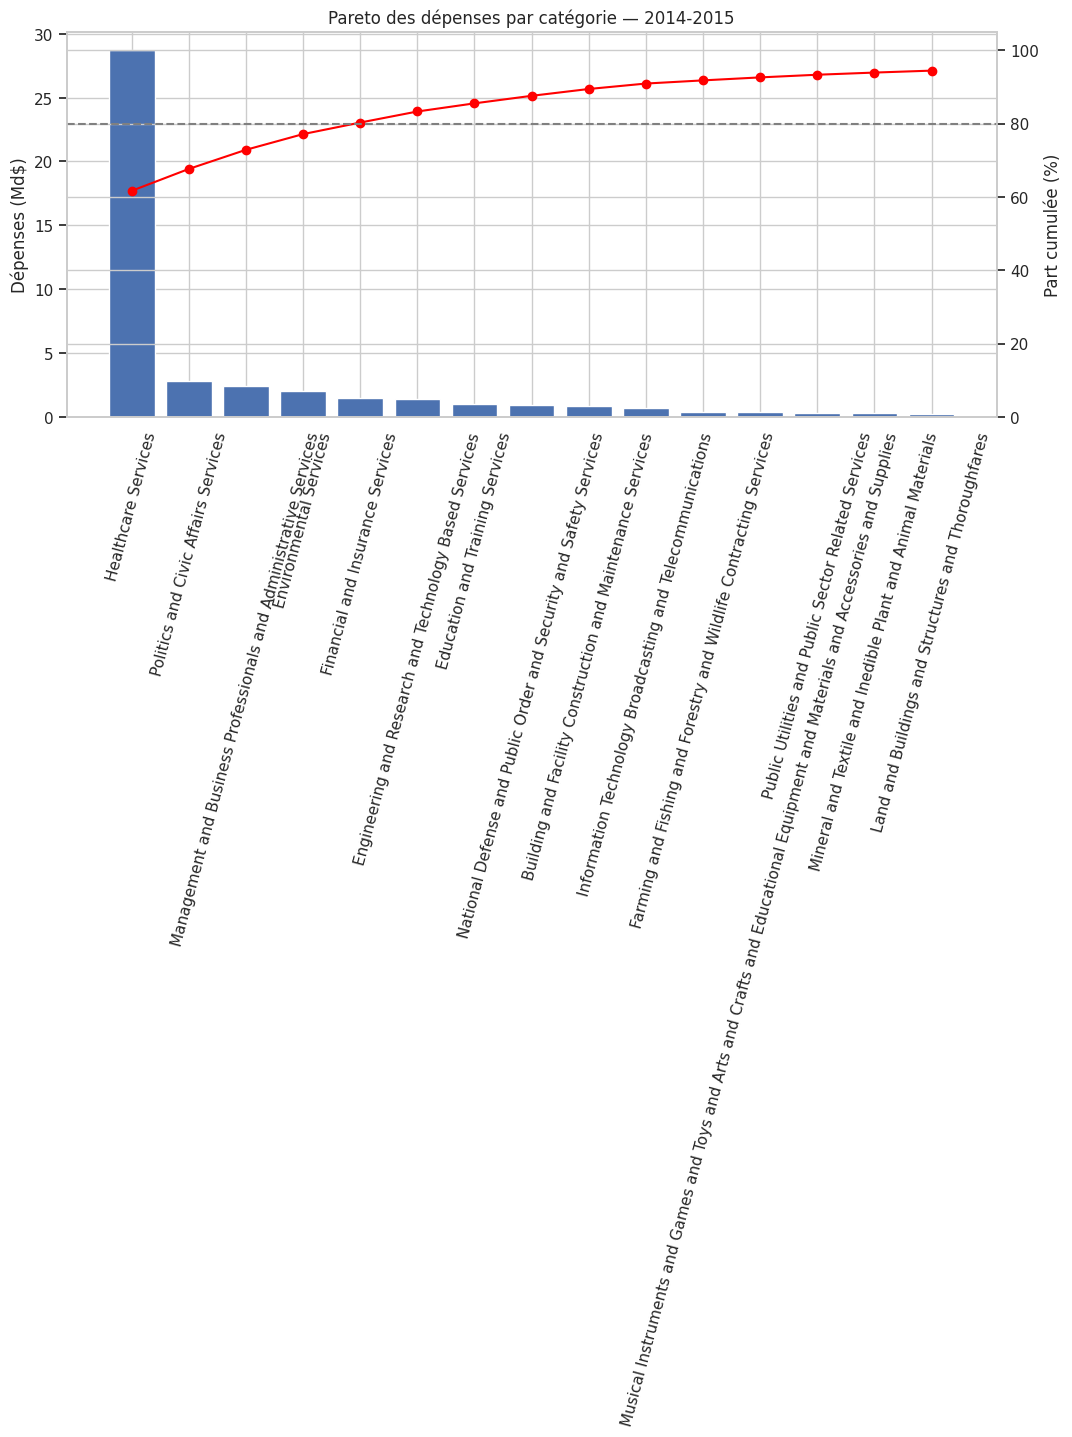

In [66]:
fig, ax1 = plt.subplots(figsize=(12, 5))

top = categories.head(15)

# Barres : dépenses
ax1.bar(top["Segment Title"], top["Dépenses"] / 1e9)
ax1.set_ylabel("Dépenses (Md$)")
ax1.tick_params(axis="x", rotation=75)

# Courbe : part cumulée
ax2 = ax1.twinx()
ax2.plot(top["Segment Title"], top["Cumul (%)"],
         color="red", marker="o")
ax2.axhline(80, color="gray", linestyle="--")
ax2.set_ylabel("Part cumulée (%)")
ax2.set_ylim(0, 105)

plt.title("Pareto des dépenses par catégorie — 2014-2015")
plt.tight_layout()
plt.show()

In [70]:
# Dépenses par année et catégorie
evolution = df_clean.pivot_table(
    index="Segment Title",
    columns="Fiscal Year",
    values="Total Price",
    aggfunc="sum",
    fill_value=0
)

# Variation entre la première et la dernière année
evolution["Variation (%)"] = (
    (evolution["2014-2015"] - evolution["2012-2013"])
    / evolution["2012-2013"].replace(0, float("nan"))
    * 100
)

# Catégories les plus coûteuses en 2014-2015
top_categories = categories.head(20)["Segment Title"]

display(
    evolution.loc[top_categories].style.format({
        "2012-2013": "{:,.2f} $",
        "2013-2014": "{:,.2f} $",
        "2014-2015": "{:,.2f} $",
        "Variation (%)": "{:+.2f} %"
    })
)

Fiscal Year,2012-2013,2013-2014,2014-2015,Variation (%)
Segment Title,,,,
Healthcare Services,"52,270,621,356.00 $","30,609,296,171.10 $","28,706,668,194.16 $",-45.08 %
Politics and Civic Affairs Services,"450,132,807.62 $","700,156,302.24 $","2,776,840,983.07 $",+516.89 %
Management and Business Professionals and Administrative Services,"1,271,972,514.28 $","1,523,868,812.16 $","2,426,805,377.50 $",+90.79 %
Environmental Services,"192,638,400.92 $","437,156,995.34 $","1,993,167,850.58 $",+934.67 %
Financial and Insurance Services,"244,219,206.11 $","517,557,919.96 $","1,464,843,389.97 $",+499.81 %
Engineering and Research and Technology Based Services,"1,080,190,798.18 $","1,821,669,953.08 $","1,403,738,826.63 $",+29.95 %
Education and Training Services,"1,689,798,005.24 $","629,521,742.37 $","1,034,049,989.97 $",-38.81 %
National Defense and Public Order and Security and Safety Services,"145,584,315.07 $","954,585,224.15 $","955,675,324.61 $",+556.44 %
Building and Facility Construction and Maintenance Services,"678,065,441.12 $","351,921,492.73 $","866,325,906.79 $",+27.76 %


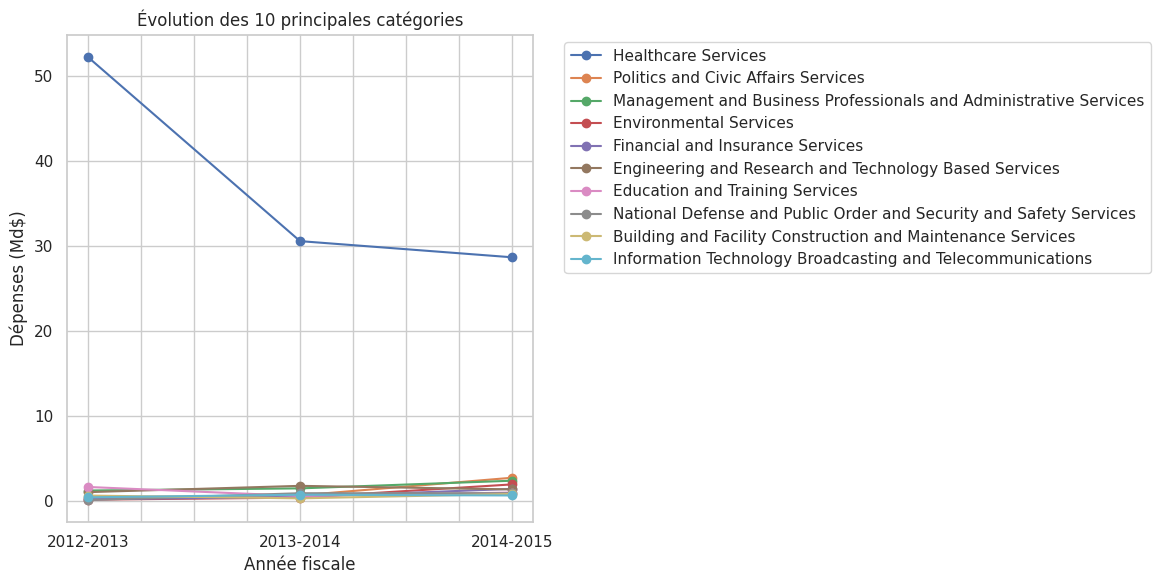

In [68]:
(
    evolution.loc[top_categories,
                  ["2012-2013", "2013-2014", "2014-2015"]]
    .T / 1e9
).plot(figsize=(12, 6), marker="o")

plt.title("Évolution des 10 principales catégories")
plt.ylabel("Dépenses (Md$)")
plt.xlabel("Année fiscale")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [69]:
priorites = df_2015.groupby("Segment Title").agg(
    Depenses=("Total Price", "sum"),
    Fournisseurs=("Supplier Code", "nunique"),
    Commandes=("Purchase Order Number", "nunique")
)

priorites["Part budget (%)"] = (
    priorites["Depenses"] / budget_reference * 100
)

priorites["Variation (%)"] = evolution["Variation (%)"]

priorites = priorites.sort_values("Depenses", ascending=False)

display(
    priorites.head(15).style.format({
        "Depenses": "{:,.2f} $",
        "Part budget (%)": "{:.2f} %",
        "Variation (%)": "{:+.2f} %"
    })
)

,Depenses,Fournisseurs,Commandes,Part budget (%),Variation (%)
Segment Title,,,,,
Healthcare Services,"28,706,668,194.16 $",928,1873,61.68 %,-45.08 %
Politics and Civic Affairs Services,"2,776,840,983.07 $",629,1181,5.97 %,+516.89 %
Management and Business Professionals and Administrative Services,"2,426,805,377.50 $",1043,2799,5.21 %,+90.79 %
Environmental Services,"1,993,167,850.58 $",323,521,4.28 %,+934.67 %
Financial and Insurance Services,"1,464,843,389.97 $",166,338,3.15 %,+499.81 %
Engineering and Research and Technology Based Services,"1,403,738,826.63 $",1308,3877,3.02 %,+29.95 %
Education and Training Services,"1,034,049,989.97 $",1344,2882,2.22 %,-38.81 %
National Defense and Public Order and Security and Safety Services,"955,675,324.61 $",346,628,2.05 %,+556.44 %
Building and Facility Construction and Maintenance Services,"866,325,906.79 $",1155,2250,1.86 %,+27.76 %


In [71]:
# Top 20 des sous-catégories en 2014-2015
sous_categories = (
    df_2015.groupby(
        ["Segment Title", "Commodity Title"]
    )["Total Price"]
    .sum()
    .sort_values(ascending=False)
    .reset_index(name="Dépenses")
)

sous_categories["Part budget (%)"] = (
    sous_categories["Dépenses"] / budget_reference * 100
)

display(
    sous_categories.head(20).style.format({
        "Dépenses": "{:,.2f} $",
        "Part budget (%)": "{:.2f} %"
    })
)

,Segment Title,Commodity Title,Dépenses,Part budget (%)
0,Healthcare Services,Public health administration,"27,568,139,363.96 $",59.23 %
1,Environmental Services,Environmental technology advisory services,"1,368,507,400.00 $",2.94 %
2,Politics and Civic Affairs Services,Administrative agencies services,"914,119,821.86 $",1.96 %
3,Financial and Insurance Services,Financial assistance,"908,064,682.02 $",1.95 %
4,Politics and Civic Affairs Services,Urban project or program administration or management services,"856,278,417.03 $",1.84 %
5,Management and Business Professionals and Administrative Services,Temporary medical staffing needs,"806,425,351.57 $",1.73 %
6,Management and Business Professionals and Administrative Services,Information technology consultation services,"537,733,162.06 $",1.16 %
7,Engineering and Research and Technology Based Services,Architectural engineering,"473,695,202.57 $",1.02 %
8,Politics and Civic Affairs Services,Tax systems,"398,937,334.00 $",0.86 %
9,Education and Training Services,Re training or refreshing training services,"336,092,927.74 $",0.72 %


##### Analyse approfondie de la catégorie Healthcare Services

Je descends progressivement en granularité, de la catégorie globale vers les départements et les lignes de dépense, afin de comprendre l'origine des montants les plus élevés. Les commandes exceptionnellement coûteuses, notamment lorsqu'elles sont associées à une classification « Unknown », sont **des priorités de vérification**, et non des dépenses automatiquement évitables.


In [72]:
healthcare = df_2015[
    df_2015["Segment Title"] == "Healthcare Services"
]

analyse_healthcare = (
    healthcare.groupby("Commodity Title")
    .agg(
        Depenses=("Total Price", "sum"),
        Fournisseurs=("Supplier Code", "nunique"),
        Commandes=("Purchase Order Number", "nunique")
    )
    .sort_values("Depenses", ascending=False)
)

analyse_healthcare["Part Healthcare (%)"] = (
    analyse_healthcare["Depenses"]
    / healthcare["Total Price"].sum() * 100
)

display(
    analyse_healthcare.head(15).style.format({
        "Depenses": "{:,.2f} $",
        "Part Healthcare (%)": "{:.2f} %"
    })
)

,Depenses,Fournisseurs,Commandes,Part Healthcare (%)
Commodity Title,,,,
Public health administration,"27,568,139,363.96 $",470,951,96.03 %
Nutrition programming services,"241,345,908.97 $",13,15,0.84 %
Energy work,"144,453,124.13 $",52,99,0.50 %
Psychologists services,"102,922,835.32 $",38,59,0.36 %
Nursing services,"102,770,053.31 $",28,32,0.36 %
Rehabilitation services for substance abuse,"74,371,847.15 $",20,37,0.26 %
Personal care services in specialized institutions,"63,514,429.48 $",20,22,0.22 %
Psychiatrist services,"61,905,426.20 $",13,15,0.22 %
Emergency or surgical hospital services,"56,771,391.99 $",15,17,0.20 %


In [73]:
environment = df_clean[
    df_clean["Segment Title"] == "Environmental Services"
]

evolution_environment = environment.pivot_table(
    index="Commodity Title",
    columns="Fiscal Year",
    values="Total Price",
    aggfunc="sum",
    fill_value=0
)

evolution_environment["Hausse ($)"] = (
    evolution_environment["2014-2015"]
    - evolution_environment["2012-2013"]
)

display(
    evolution_environment.sort_values(
        "Hausse ($)", ascending=False
    ).head(15).style.format("{:,.2f} $")
)

Fiscal Year,2012-2013,2013-2014,2014-2015,Hausse ($)
Commodity Title,,,,
Environmental technology advisory services,"63,000.00 $","87,009.00 $","1,368,507,400.00 $","1,368,444,400.00 $"
Environmental standards,"2,690,603.00 $","169,532,347.00 $","160,360,716.63 $","157,670,113.63 $"
Environmental Impact Assessment EIA services,"10,187,607.47 $","68,604,732.00 $","123,292,795.95 $","113,105,188.48 $"
Legal compliance certification service,0.00 $,"50,000.00 $","50,066,706.00 $","50,066,706.00 $"
Environmental monitoring,"8,884,433.62 $","13,599,185.00 $","43,300,109.22 $","34,415,675.60 $"
Risk or hazard assessment,"3,569,045.00 $","13,339,060.00 $","33,503,938.15 $","29,934,893.15 $"
Soil pollution protection services,0.00 $,"127,000.00 $","24,790,000.00 $","24,790,000.00 $"
Air pollution protection services,"1,720,780.00 $","29,916.00 $","21,572,801.00 $","19,852,021.00 $"
Endangered species protection services,"5,923,179.96 $","7,499,107.51 $","19,012,378.96 $","13,089,199.00 $"


In [74]:
# Examiner les principales commandes Sous-catégories à examiner
cibles = [
    "Public health administration",
    "Environmental technology advisory services"
]

investigation = df_2015[
    df_2015["Commodity Title"].isin(cibles)
]

# Dépenses par commande et fournisseur
commandes = (
    investigation.groupby([
        "Commodity Title",
        "Purchase Order Number",
        "Supplier Name"
    ], dropna=False)["Total Price"]
    .sum()
    .sort_values(ascending=False)
    .reset_index(name="Dépenses")
)

display(
    commandes.head(20).style.format({
        "Dépenses": "{:,.2f} $"
    })
)

,Commodity Title,Purchase Order Number,Supplier Name,Dépenses
0,Public health administration,10-87050,Fresno-Kings-Madera Regional Health Authority,"3,509,792,000.00 $"
1,Public health administration,10-87128,Ventura County,"2,904,373,000.00 $"
2,Public health administration,12-89334,"Health Net Community Solutions, Inc.","2,814,351,000.00 $"
3,Public health administration,08-85215,Partnership HealthPlan of California,"2,618,879,102.03 $"
4,Public health administration,09-86155,Community Health Group Partnership Plan,"2,468,126,000.00 $"
5,Public health administration,08-85213,San Mateo Health Commission dba: Health Plan of San Mateo,"2,141,810,000.03 $"
6,Public health administration,08-85214,"ORANGE COUNTY HEALTH AUTHORITY, DBA CALOPTIMA","2,091,639,000.03 $"
7,Public health administration,10-87049,"Blue Cross of California Partnership Plan, Inc.","1,993,223,000.00 $"
8,Environmental technology advisory services,HSR13-57,Unknown,"1,365,335,890.00 $"
9,Public health administration,12-89224,County Of Los Angeles,"480,909,476.00 $"


In [75]:
# Examiner les descriptions des achats
colonnes = [
    "Commodity Title",
    "Department Name",
    "Supplier Name",
    "Item Description",
    "Acquisition Method",
    "Total Price"
]

display(
    investigation.nlargest(20, "Total Price")[colonnes]
    .style.format({"Total Price": "{:,.2f} $"})
)

,Commodity Title,Department Name,Supplier Name,Item Description,Acquisition Method,Total Price
241661,Public health administration,"Health Care Services, Department of",Ventura County,Provide health care services to eligible Medi-Cal Recipients.,Services are specifically exempt by policy,"1,979,109,000.00 $"
337671,Public health administration,"Health Care Services, Department of","Health Net Community Solutions, Inc.",Funding adj. New Contract,Services are specifically exempt by statute,"1,949,122,000.00 $"
265583,Public health administration,"Health Care Services, Department of",Fresno-Kings-Madera Regional Health Authority,Provide health care services to enrolled Medi-Cal beneficiaries.,Services are specifically exempt by statute,"1,592,310,000.00 $"
195063,Public health administration,"Health Care Services, Department of","Blue Cross of California Partnership Plan, Inc.",Provide health care services to enrolled Medi-Cal beneficiaries.,Services are specifically exempt by statute,"1,563,297,000.00 $"
191549,Public health administration,"Health Care Services, Department of",Fresno-Kings-Madera Regional Health Authority,Amendment A01a Incorporates SB 90 Quality Assurance Fee (QAF) Rates.,Services are specifically exempt by statute,"1,491,999,000.00 $"
187014,Environmental technology advisory services,"High Speed Rail Authority, California",Unknown,"CP 2-3, which was awarded to Dragados/Flatiron, follows CP 1, continuing construction to the south. CP 2-3 extends approximately 65 miles from the terminus of CP 1 at East American Avenue in Fresno to one mile north of the Kern-Tulare County line. CP 2-",Formal Competitive,"1,365,335,890.00 $"
176656,Public health administration,"Health Care Services, Department of",Partnership HealthPlan of California,"Amendment A02 adds Sonoma County, increases the budget, and adjusts rates.",Informal Competitive,"1,245,472,000.00 $"
179234,Public health administration,"Health Care Services, Department of",Community Health Group Partnership Plan,Provide health care services to enrolled Medi-Cal beneficiaries.,Services are specifically exempt by statute,"1,096,855,000.00 $"
179442,Public health administration,"Health Care Services, Department of",San Mateo Health Commission dba: Health Plan of San Mateo,Provide health care services to eligible Medi-Cal recipients.,Informal Competitive,"1,085,954,000.00 $"
174422,Public health administration,"Health Care Services, Department of","ORANGE COUNTY HEALTH AUTHORITY, DBA CALOPTIMA",Amendment A05 incorporates rates.,Informal Competitive,"1,036,790,000.00 $"


In [76]:
fournisseurs = (
    investigation.groupby(
        ["Commodity Title", "Supplier Name"]
    )["Total Price"]
    .sum()
    .reset_index(name="Dépenses")
)

fournisseurs["Part (%)"] = (
    fournisseurs["Dépenses"]
    / fournisseurs.groupby("Commodity Title")["Dépenses"].transform("sum")
    * 100
)

display(
    fournisseurs.sort_values(
        ["Commodity Title", "Dépenses"],
        ascending=[True, False]
    ).groupby("Commodity Title").head(10)
    .style.format({
        "Dépenses": "{:,.2f} $",
        "Part (%)": "{:.2f} %"
    })
)

,Commodity Title,Supplier Name,Dépenses,Part (%)
4,Environmental technology advisory services,Unknown,"1,365,335,890.00 $",99.77 %
2,Environmental technology advisory services,DUCKS UNLIMITED INC,"2,480,610.00 $",0.18 %
3,Environmental technology advisory services,ICF Jones & Stokes,"570,900.00 $",0.04 %
1,Environmental technology advisory services,CALIFORNIA RURAL WATER ASSOCIATION,"100,000.00 $",0.01 %
0,Environmental technology advisory services,Aquatic Science Center,"20,000.00 $",0.00 %
222,Public health administration,Fresno-Kings-Madera Regional Health Authority,"3,509,792,000.00 $",12.73 %
446,Public health administration,Ventura County,"2,906,347,212.00 $",10.54 %
234,Public health administration,"Health Net Community Solutions, Inc.","2,823,734,000.00 $",10.24 %
335,Public health administration,Partnership HealthPlan of California,"2,618,879,102.03 $",9.50 %
135,Public health administration,Community Health Group Partnership Plan,"2,468,126,000.00 $",8.95 %


In [77]:
# hypothese que La baisse historique peu induire une nouvelle baisse ( coup au long terme)
depenses = df_clean.pivot_table(index="Segment Title", columns="Fiscal Year", values="Total Price", aggfunc="sum", fill_value=0)
depenses["Variation récente (%)"] = (depenses["2014-2015"] / depenses["2013-2014"].replace(0, np.nan)-1)*100
display(depenses.sort_values("2014-2015", ascending=False).head(15))

Fiscal Year,2012-2013,2013-2014,2014-2015,Variation récente (%)
Segment Title,,,,
Healthcare Services,"52,270,621,356.00","30,609,296,171.10","28,706,668,194.16",-6.22
Politics and Civic Affairs Services,"450,132,807.62","700,156,302.24","2,776,840,983.07",296.60
Management and Business Professionals and Administrative Services,"1,271,972,514.28","1,523,868,812.16","2,426,805,377.50",59.25
Environmental Services,"192,638,400.92","437,156,995.34","1,993,167,850.58",355.94
Financial and Insurance Services,"244,219,206.11","517,557,919.96","1,464,843,389.97",183.03
Engineering and Research and Technology Based Services,"1,080,190,798.18","1,821,669,953.08","1,403,738,826.63",-22.94
Education and Training Services,"1,689,798,005.24","629,521,742.37","1,034,049,989.97",64.26
National Defense and Public Order and Security and Safety Services,"145,584,315.07","954,585,224.15","955,675,324.61",0.11
Building and Facility Construction and Maintenance Services,"678,065,441.12","351,921,492.73","866,325,906.79",146.17


## Recommandations et scénarios d’économies

**Principe :** cibler des assiettes vérifiables, ne pas assimiler les hausses à des investissements, ne pas extrapoler mécaniquement les baisses passées, et éviter le double comptage.

In [80]:
# === ANALYSE D'OPPORTUNITÉS
# Les montants ci-dessous sont des scénarios, pas des économies réalisées.
from pathlib import Path
OUT = Path("resultats_procurement"); OUT.mkdir(exist_ok=True)
last_year = "2014-2015"
base = df_clean[df_clean["Fiscal Year"] == last_year].copy()
budget = base["Total Price"].sum()
objectif = .05 * budget
print(f"Budget de référence : {budget:,.0f} $ | Cible 5 % : {objectif:,.0f} $")


Budget de référence : 46,541,293,689 $ | Cible 5 % : 2,327,064,684 $


### 1. Identifier les achats potentiellement non récurrents
On cherche le schéma :

**2012–2013 : dépenses élevées → 2013–2014 : baisse → 2014–2015 : nouvelle hauss**

In [89]:
# 1. Achats potentiellement non récurrents

annees = ["2012-2013", "2013-2014", "2014-2015"]
cles = ["Department Name", "Segment Title"]

evol = df_clean.pivot_table(
    index=cles,
    columns="Fiscal Year",
    values="Total Price",
    aggfunc="sum",
    fill_value=0
).reindex(columns=annees, fill_value=0)

evol.columns = ["2012", "2013", "2014"]

# Garder uniquement les dépenses présentes les 3 années
evol = evol[(evol[["2012", "2013", "2014"]] > 0).all(axis=1)].copy()

# Scénario : baisse en 2014, puis hausse en 2015
ponctuels = evol[
    (evol["2012"] > evol["2013"]) &
    (evol["2014"] > evol["2013"])
].copy()

# Variations historiques
ponctuels["Baisse 2013 (%)"] = (
    (1 - ponctuels["2013"] / ponctuels["2012"]) * 100
)

ponctuels["Hausse 2014 (%)"] = (
    (ponctuels["2014"] / ponctuels["2013"] - 1) * 100
)

# Proposer une baisse légèrement inférieure à celle de 2014
# Sans dépasser le retour au niveau de dépenses de 2014
ponctuels["Baisse proposee (%)"] = np.minimum(
    ponctuels["Baisse 2013 (%)"] * 0.80,
    (1 - ponctuels["2013"] / ponctuels["2014"]) * 100
)

# Economies estimées pour 2016
ponctuels["Economie estimee ($)"] = (
    ponctuels["2014"] * ponctuels["Baisse proposee (%)"] / 100
)

# Confiance indicative : cohérence des variations
# Ce score ne représente PAS une probabilité de réalisation.
ecart = abs(
    ponctuels["Baisse 2013 (%)"] -
    ponctuels["Hausse 2014 (%)"]
)

ponctuels["Confiance"] = np.select(
    [ecart <= 10, ecart <= 25],
    ["Moyenne", "Faible"],
    default="Très faible"
)

ponctuels = ponctuels.sort_values(
    "Economie estimee ($)", ascending=False
)

# Tableau détaillé : département + catégorie
display(ponctuels.head(20).round(2))

# Tableau récapitulatif par département
par_departement = ponctuels.groupby(level=0).agg({
    "2012": "sum",
    "2013": "sum",
    "2014": "sum",
    "Economie estimee ($)": "sum"
})

par_departement["Baisse proposee (%)"] = (
    par_departement["Economie estimee ($)"] /
    par_departement["2014"] * 100
)

par_departement = par_departement.sort_values(
    "Economie estimee ($)", ascending=False
)

display(par_departement.head(20).round(2))

# Bilan global
gain_ponctuel = ponctuels["Economie estimee ($)"].sum()

# Objectif = 5 % des dépenses de 2015
budget = df_clean.loc[
    df_clean["Fiscal Year"] == "2013-2014", "Total Price"
].sum()

objectif = budget * 0.05

print("\n===== BILAN DES ECONOMIES =====")
print(f"Budget 2014 : {budget:,.2f} $")
print(f"Objectif de réduction (5 %) : {objectif:,.2f} $")
print(f"Economies estimées : {gain_ponctuel:,.2f} $")
print(f"Réduction du budget : {gain_ponctuel / budget * 100:.2f} %")
print(f"Part de l'objectif atteinte : {gain_ponctuel / objectif * 100:.2f} %")
print(f"Reste à économiser : {max(objectif - gain_ponctuel, 0):,.2f} $")
print("Confiance globale : faible (hypothèse de non-renouvellement non vérifiée)")

2012  \
Department Name                                   Segment Title                                                                         
Public Health, Department of                      Healthcare Services                                                3,688,869,242.64   
Social Services, Department of                    Financial and Insurance Services                                      90,370,329.75   
                                                  Management and Business Professionals and Administrative Services    457,554,483.19   
                                                  Politics and Civic Affairs Services                                  131,091,684.12   
Correctional Health Care Services                 Management and Business Professionals and Administrative Services     65,031,756.30   
Consumer Affairs, Department of                   Mineral and Textile and Inedible Plant and Animal Materials          152,516,923.93   
Human Resources, California Department of         Financial and Insurance Services                                      29,245,305.00   
Water Resources, Department of                    Environmental Services                                                69,685,590.00   
Community Services and Development, Department of Public Utilities and Public Sector Related Services                  255,631,238.00   
Employment Development Department                 Education and Training Services                                      601,920,126.89   
                                                  Engineering and Research and Technology Based Services                26,979,624.47   
Social Services, Department of                    Engineering and Research and Technology Based Services                17,243,059.09   
Employment Development Department                 Information Technology Broadcasting and Telecommunications            57,145,248.41   
Water Resources, Department of                    Financial and Insurance Services                                         429,960.00   
Social Services, Department of                    Education and Training Services                                      824,288,817.71   
High Speed Rail Authority, California             Farming and Fishing and Forestry and Wildlife Contracting Services     8,973,851.00   
Corrections and Rehabilitation, Department of     Building and Facility Construction and Maintenance Services          141,477,833.51   
Motor Vehicles, Department of                     Financial and Insurance Services                                       1,476,000.01   
Highway Patrol, California                        Information Technology Broadcasting and Telecommunications            42,117,322.60   
Food and Agriculture, Department of               Transportation and Storage and Mail Services                           2,961,261.13   

                                                                                                                               2013  \
Department Name                                   Segment Title                                                                       
Public Health, Department of                      Healthcare Services                                                516,805,896.98   
Social Services, Department of                    Financial and Insurance Services                                     1,802,215.00   
                                                  Management and Business Professionals and Administrative Services   14,624,863.99   
                                                  Politics and Civic Affairs Services                                 92,629,805.10   
Correctional Health Care Services                 Management and Business Professionals and Administrative Services   41,089,028.04   
Consumer Affairs, Department of                   Mineral and Textile and Inedible Plant and Animal Materials          2,546,316.60   
Human Resources, California Depart

,2012,2013,2014,Economie estimee ($),Baisse proposee (%)
Department Name,,,,,
"Social Services, Department of","1,573,645,921.17","136,937,447.14","2,712,031,817.57","1,445,475,736.86",53.30
"Public Health, Department of","3,714,123,133.43","532,110,801.24","1,234,066,707.77","643,778,766.48",52.17
Employment Development Department,"704,880,159.40","225,847,921.55","627,775,683.15","281,372,177.94",44.82
"Water Resources, Department of","115,224,722.71","45,056,889.18","387,948,311.63","205,207,955.44",52.90
"Consumer Affairs, Department of","179,399,853.82","11,203,287.91","268,803,556.41","199,746,668.96",74.31
Correctional Health Care Services,"88,873,751.16","58,638,067.29","634,133,879.93","183,567,666.35",28.95
"Human Resources, California Department of","30,166,187.00","1,276,870.00","217,427,667.00","168,361,333.63",77.43
"Community Services and Development, Department of","255,970,036.31","111,434,047.54","271,688,942.75","122,714,132.52",45.17
"General Services, Department of","49,945,817.38","23,536,349.22","179,668,460.14","80,484,580.10",44.80



===== BILAN DES ECONOMIES =====
Budget 2014 : 42,273,000,633.08 $
Objectif de réduction (5 %) : 2,113,650,031.65 $
Economies estimées : 3,953,273,880.38 $
Réduction du budget : 9.35 %
Part de l'objectif atteinte : 187.04 %
Reste à économiser : 0.00 $
Confiance globale : faible (hypothèse de non-renouvellement non vérifiée)


#### Concentration sur les Goods et pas les service

In [97]:
# 1. Filtrer uniquement les biens
goods = df_clean[df_clean["Acquisition Type"].isin(["IT Goods", "NON-IT Goods"])]

# 2. Evolution des dépenses par département et catégorie
evol = goods.pivot_table(
    index=["Department Name", "Segment Title"],
    columns="Fiscal Year", values="Total Price",
    aggfunc="sum", fill_value=0
).reindex(columns=["2012-2013", "2013-2014", "2014-2015"], fill_value=0)

evol.columns = ["2013", "2014", "2015"]

# 3. Scénario : baisse en 2014 puis hausse en 2015
ponctuels_goods = evol[
    (evol[["2013", "2014", "2015"]] > 0).all(axis=1) &
    (evol["2013"] > evol["2014"]) &
    (evol["2015"] > evol["2014"])
].copy()

# 4. Variations et baisse proposée (80 % de la baisse historique)
p = ponctuels_goods
p["Baisse 2014 (%)"] = (1 - p["2014"] / p["2013"]) * 100
p["Hausse 2015 (%)"] = (p["2015"] / p["2014"] - 1) * 100

p["Baisse proposée (%)"] = np.minimum(
    p["Baisse 2014 (%)"] * 0.8,
    (1 - p["2014"] / p["2015"]) * 100
)

p["Économie estimée ($)"] = p["2015"] * p["Baisse proposée (%)"] / 100

# 5. Résultats
display(p.sort_values("Économie estimée ($)", ascending=False).head(20).round(2))

# 6. Bilan par département
par_departement = p.groupby(level=0).agg({
    "2015": "sum",
    "Économie estimée ($)": "sum"
}).sort_values("Économie estimée ($)", ascending=False)

display(par_departement.round(2))

# 7. Contribution à l'objectif de 5 %
budget = df_clean.loc[df_clean["Fiscal Year"] == "2014-2015", "Total Price"].sum()
objectif = budget * 0.05
gain_goods = p["Économie estimée ($)"].sum()

print(f"Économies estimées : {gain_goods:,.2f} $")
print(f"Réduction du budget global : {gain_goods / budget * 100:.2f} %")
print(f"Objectif de 5 % atteint à : {gain_goods / objectif * 100:.2f} %")
print(f"Reste à économiser : {max(objectif - gain_goods, 0):,.2f} $")

,,2013,2014,2015,Baisse 2014 (%),Hausse 2015 (%),Baisse proposée (%),Économie estimée ($)
Department Name,Segment Title,,,,,,,
"High Speed Rail Authority, California",Farming and Fishing and Forestry and Wildlife Contracting Services,"8,932,851.00","199,088.00","42,500,000.00",97.77,"21,247.34",78.22,"33,242,236.10"
"Public Health, Department of",Medical Equipment and Accessories and Supplies,"4,425,070.15","2,914,651.68","52,749,667.58",34.13,"1,709.81",27.31,"14,404,123.69"
"Highway Patrol, California",Information Technology Broadcasting and Telecommunications,"5,351,157.08","3,346,066.14","30,409,040.01",37.47,808.80,29.98,"9,115,470.12"
"Public Health, Department of",Laboratory and Measuring and Observing and Testing Equipment,"3,452,636.61","979,886.10","12,051,921.89",71.62,"1,129.93",57.30,"6,905,191.45"
Correctional Health Care Services,Information Technology Broadcasting and Telecommunications,"16,654,002.57","9,728,894.87","19,067,816.67",41.58,95.99,33.27,"6,343,060.58"
"Justice, Department of",Laboratory and Measuring and Observing and Testing Equipment,"13,592,858.73","1,073,496.60","7,091,024.02",92.10,560.55,73.68,"5,224,808.08"
"Forestry and Fire Protection, Department of",Food Beverage and Tobacco Products,"5,728,552.79","2,723,579.09","9,189,809.55",52.46,237.42,41.96,"3,856,490.39"
"Transportation, Department of",Chemicals including Bio Chemicals and Gas Materials,"8,556,241.50","3,736,464.99","8,074,264.44",56.33,116.09,45.06,"3,638,621.01"
"General Services, Department of",Information Technology Broadcasting and Telecommunications,"8,427,271.54","5,103,498.01","9,766,802.57",39.44,91.37,31.55,"3,081,674.98"


,2015,Économie estimée ($)
Department Name,,
"High Speed Rail Authority, California","42,500,000.00","33,242,236.10"
"Public Health, Department of","77,792,153.21","23,773,828.66"
"Transportation, Department of","77,512,228.83","15,913,913.34"
"Highway Patrol, California","36,797,366.80","11,331,851.77"
"Forestry and Fire Protection, Department of","24,608,799.68","8,972,259.97"
"Corrections and Rehabilitation, Department of","62,194,864.72","7,832,612.23"
Correctional Health Care Services,"23,728,336.21","7,529,275.25"
"Justice, Department of","11,951,799.37","6,779,181.58"
"General Services, Department of","21,187,424.89","5,405,924.68"


Économies estimées : 144,231,626.54 $
Réduction du budget global : 0.31 %
Objectif de 5 % atteint à : 6.20 %
Reste à économiser : 2,182,833,057.89 $


### 2. Harmonisation des prix entre fournisseurs
**Ici, on cherche les mêmes articles achetés à des prix différents.**

On fait le matching des articles sur deux colonnes :
1. **Normalized UNSPSC** : code de classification du produit.
2. **Item Name** : nom de l'article, converti en minuscules et sans espaces au début ou à la fin



In [99]:
# 2. Harmonisation des prix entre fournisseurs

prix = df_prix[
    (df_prix["Fiscal Year"] == last_year) &
    (df_prix["Acquisition Type"].isin(["IT Goods", "NON-IT Goods"])) &
    (df_prix["Unit Price"] > 0) &
    (df_prix["Quantity"] > 0)
].copy()

# Identifier les articles identiques
prix["article"] = prix["Item Name"].fillna("").str.lower().str.strip()
prix["code"] = prix["Normalized UNSPSC"].fillna("").astype(str).str.strip()

prix = prix[
    (prix["article"].str.len() >= 5) &
    (prix["code"].str.len() >= 4) &
    prix["Supplier Code"].notna()
].copy()

prix["cle"] = prix["code"] + " | " + prix["article"]

# Comparer les fournisseurs
stats = prix.groupby("cle").agg(
    fournisseurs=("Supplier Code", "nunique"),
    prix_min=("Unit Price", "min"),
    prix_max=("Unit Price", "max")
)

stats = stats[stats["fournisseurs"] >= 2]
prix = prix.join(stats, on="cle", how="inner")

# Economies si tous les achats utilisent le prix minimum observé
prix["gain_theorique"] = (
    (prix["Unit Price"] - prix["prix_min"]).clip(lower=0)
    * prix["Quantity"]
)

# Résultats par article
bench = prix.groupby("cle").agg(
    depense=("Total Price", "sum"),
    gain=("gain_theorique", "sum"),
    fournisseurs=("Supplier Code", "nunique"),
    departements=("Department Name", "nunique"),
    prix_min=("prix_min", "min"),
    prix_max=("prix_max", "max")
).sort_values("gain", ascending=False)

display(bench.head(20).round(2))

# Contribution à l'objectif
gain_prix = bench["gain"].sum()
budget = df_clean.loc[df_clean["Fiscal Year"] == last_year, "Total Price"].sum()
objectif = budget * 0.05

print(f"Economies potentielles : {gain_prix:,.2f} $")
print(f"Réduction du budget : {gain_prix / budget * 100:.2f} %")
print(f"Objectif de 5 % atteint à : {gain_prix / objectif * 100:.2f} %")
print(f"Reste à économiser : {max(objectif - gain_prix, 0):,.2f} $")

,depense,gain,fournisseurs,departements,prix_min,prix_max
cle,,,,,,
30121601 | asphalt,"14,317,624.18","13,915,296.18",53,4,8.00,"799,999.34"
15101801 | biodiesel,"13,100,000.00","11,840,000.00",2,1,"420,000.00","11,000,000.00"
15101505 | diesel,"5,897,730.10","5,752,928.10",19,7,1.00,"5,000,000.00"
50181901 | bread,"4,998,300.15","4,863,076.00",9,5,0.13,"548,601.40"
46101601 | ammunition,"4,887,879.38","4,839,187.92",16,11,0.24,"420,240.00"
43211503 | laptops,"6,130,300.29","4,726,118.29",8,17,689.00,"727,720.89"
43231512 | software license,"4,749,740.97","4,700,942.38",33,16,8.81,"1,093,479.85"
43211507 | desktops,"4,374,368.70","4,107,462.70",3,7,226.00,"2,555,396.00"
43231512 | software licenses,"4,000,942.27","3,975,202.27",16,7,143.00,"3,192,484.00"


Economies potentielles : 286,870,202.80 $
Réduction du budget : 0.62 %
Objectif de 5 % atteint à : 12.33 %
Reste à économiser : 2,040,194,481.64 $


### 3. Prolonger les tendances de réduction historiques
**Pour cette stratégie, on s'intéresse aux départements dont les dépenses ont diminué pendant les deux transitions :**
- De 2012–2013 à 2013–2014.
- De 2013–2014 à 2014–2015.
**L'objectif est de calculer leur taux de baisse moyen, puis de proposer une réduction cohérente avec leur historique.**

In [102]:
# 3. Départements avec baisse continue et décroissante

tendance = df_clean.pivot_table(
    index="Department Name",
    columns="Fiscal Year",
    values="Total Price",
    aggfunc="sum",
    fill_value=0
).reindex(columns=annees, fill_value=0)

tendance.columns = ["2013", "2014", "2015"]

# Départements avec dépenses présentes les trois années
tendance = tendance[
    (tendance[["2013", "2014", "2015"]] > 0).all(axis=1)
].copy()

# Calcul des baisses historiques
tendance["Baisse 2014 (%)"] = (
    (1 - tendance["2014"] / tendance["2013"]) * 100
)

tendance["Baisse 2015 (%)"] = (
    (1 - tendance["2015"] / tendance["2014"]) * 100
)

# Garder uniquement les baisses successives et décroissantes
tendance = tendance[
    (tendance["Baisse 2014 (%)"] > tendance["Baisse 2015 (%)"]) &
    (tendance["Baisse 2015 (%)"] > 0)
].copy()

# Proposer 75 % de la dernière baisse
tendance["Baisse proposee (%)"] = (
    tendance["Baisse 2015 (%)"] * 0.75
)

# Economies estimées
tendance["Economie potentielle"] = (
    tendance["2015"] * tendance["Baisse proposee (%)"] / 100
)

# Trier par économies
tendance = tendance.sort_values(
    "Economie potentielle", ascending=False
)

display(tendance.head(20).round(2))

# Contribution à l'objectif de 5 %
gain_tendance = tendance["Economie potentielle"].sum()
budget = df_clean.loc[df_clean["Fiscal Year"] == last_year, "Total Price"].sum()
objectif = budget * 0.05

print(f"Economies estimées : {gain_tendance:,.2f} $")
print(f"Réduction du budget global : {gain_tendance / budget * 100:.2f} %")
print(f"Objectif de 5 % atteint à : {gain_tendance / objectif * 100:.2f} %")
print(f"Reste à économiser : {max(objectif - gain_tendance, 0):,.2f} $")

,2013,2014,2015,Baisse 2014 (%),Baisse 2015 (%),Baisse proposee (%),Economie potentielle
Department Name,,,,,,,
"Health Care Services, Department of","44,667,961,779.51","28,456,453,981.89","26,634,934,975.02",36.29,6.40,4.80,"1,278,691,654.66"
"State Hospitals, Department of","3,110,698,593.12","698,189,549.71","626,587,332.70",77.56,10.26,7.69,"48,194,335.83"
"Library, California State","7,941,650.01","4,602,962.32","2,705,789.59",42.04,41.22,30.91,"836,420.64"
"Coastal Conservancy, State","47,435,368.23","4,690,448.49","922,926.00",90.11,80.32,60.24,"555,993.39"
"Alcoholic Beverage Control, Department of","5,412,619.70","4,133,839.74","3,279,342.48",23.63,20.67,15.50,"508,399.46"
"Environmental Health Hazard Assessment, Office of","3,627,833.00","1,490,012.09","867,127.70",58.93,41.80,31.35,"271,870.43"
"Personnel Board, State","5,970,336.24","1,437,108.37","1,133,046.72",75.93,21.16,15.87,"179,796.49"
State Lands Commission,"1,821,169.87","314,801.42","265,980.18",82.71,15.51,11.63,"30,937.32"


Economies estimées : 1,329,269,408.20 $
Réduction du budget global : 2.86 %
Objectif de 5 % atteint à : 57.12 %
Reste à économiser : 997,795,276.23 $


### 4. Calculer les économies et comparer à l'objectif de 5 %

In [105]:
import pandas as pd

# Budget de référence : année 2014-2015
budget = df_clean.loc[
    df_clean["Fiscal Year"] == last_year, "Total Price"
].sum()

objectif = budget * 0.05

# Tableau récapitulatif
recap = pd.DataFrame({
    "Stratégie": [
        "1. Non-renouvellement des biens",
        "2. Harmonisation des prix",
        "3. Poursuite des baisses historiques"
    ],
    "Économies ($)": [
        gain_goods,
        gain_prix,
        gain_tendance
    ],
    "Confiance": [
        "Faible",
        "Faible à moyenne",
        "Faible à moyenne"
    ]
})

# Calcul des pourcentages
recap["Réduction budget (%)"] = (
    recap["Économies ($)"] / budget * 100
)

recap["Objectif atteint (%)"] = (
    recap["Économies ($)"] / objectif * 100
)

# Total brut des trois stratégies
total = recap["Économies ($)"].sum()

recap.loc[len(recap)] = [
    "TOTAL BRUT",
    total,
    "À valider",
    total / budget * 100,
    total / objectif * 100
]

# Affichage
display(
    recap.style.format({
        "Économies ($)": "{:,.2f} $",
        "Réduction budget (%)": "{:.2f} %",
        "Objectif atteint (%)": "{:.2f} %"
    })
)

# Bilan
print(f"\nBudget 2015 : {budget:,.0f} $")
print(f"Objectif de réduction (5 %) : {objectif:,.0f} $")
print(f"Total brut des économies : {total:,.0f} $")
print(f"Objectif couvert : {total / objectif * 100:.2f} %")
print(f"Réduction estimée du budget : {total / budget * 100:.2f} %")
print(f"Reste à économiser : {max(objectif - total, 0):,.0f} $")

,Stratégie,Économies ($),Confiance,Réduction budget (%),Objectif atteint (%)
0,1. Non-renouvellement des biens,"144,231,626.54 $",Faible,0.31 %,6.20 %
1,2. Harmonisation des prix,"286,870,202.80 $",Faible à moyenne,0.62 %,12.33 %
2,3. Poursuite des baisses historiques,"1,329,269,408.20 $",Faible à moyenne,2.86 %,57.12 %
3,TOTAL BRUT,"1,760,371,237.54 $",À valider,3.78 %,75.65 %



Budget 2015 : 46,541,293,689 $
Objectif de réduction (5 %) : 2,327,064,684 $
Total brut des économies : 1,760,371,238 $
Objectif couvert : 75.65 %
Réduction estimée du budget : 3.78 %
Reste à économiser : 566,693,447 $
